# Control de E3a: ¿qué parte de la potencia cruzada detecta la apnea?

La F elegida en E3a es el logaritmo de la **potencia cruzada RR–EDR** en la banda de apnea (0,01–0,05 Hz), con ventana de 3 min, Welch y EDR por área. En cada frecuencia, la potencia cruzada se descompone así:

$$|S_{RR,EDR}| = \sqrt{C} \cdot \sqrt{P_{RR} \cdot P_{EDR}}$$

(C: coherencia; P: potencia de cada señal). E3a mostró que la coherencia **sola** detecta mal y que multiplicar **otra vez** por ella empeora, pero no si la $\sqrt{C}$ que ya está adentro aporta. Este control lo separa.

**Diseño (fijado antes de correr).** Misma configuración que la ganadora y mismos minutos que E3a (desarrollo, 19 sujetos):
1. **F:** log de la potencia cruzada (debe reproducir el AUC de E3a).
2. **Potencias sin coherencia:** ½ (log P_RR + log P_EDR), la media geométrica de las dos potencias.
3. **Solo RR:** log P_RR (Welch, misma ventana).
4. **Solo EDR:** log P_EDR.
5. **Coherencia sola.**
6. **HRV de E4:** potencia del RR en la banda de apnea con Lomb (3 min).

Las potencias se promedian en la banda antes de tomar logaritmo, así que la descomposición vale de forma aproximada para la banda completa.

**Interpretación fijada de antemano** (no cambia F: es un análisis para entender, no para elegir):
- **La coherencia aporta** si F supera a (2) con el IC de la diferencia por encima de 0. Si (2) es no inferior a F (límite inferior de la diferencia ≥ −0,02), la coherencia no aporta de forma relevante.
- **El EDR aporta sobre el RR** si (2) supera a (3) con el IC por encima de 0.
- Se reportan todas las diferencias, con bootstrap por sujeto.

In [1]:
import os
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ["PYTHONPATH"] = str(ROOT)
from src.config import RESULTS_DIR, SPLIT_CSV
from src.features.build import record_minute_table
from src.features.variants import coupling_variants, hrv_variants
from src.stats.compare import compare_variants, orient

FIG = RESULTS_DIR / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
CACHE = RESULTS_DIR / "e3"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8})
AZUL, NARANJA, GRIS, TINTA = "#2a78d6", "#eb6834", "#a3a29c", "#2b2b2b"
split = pd.read_csv(SPLIT_CSV).set_index("record")
DEV = list(split.index[split.set == "dev"])
GANADORA = pd.read_json(CACHE / "seleccion_e3a.json", typ="series")["acoplamiento"]
print("F de E3a:", GANADORA)

F de E3a: area|180s|welch3|apnea|potencia sola


In [2]:
# Mismos minutos que E3a: se reconstruye su filtro a partir de las tablas guardadas.
coup = pd.read_parquet(CACHE / "acoplamiento.parquet")
hrv = pd.read_parquet(CACHE / "hrv.parquet")
wide_c, _ = coupling_variants(coup)
wide_h, _ = hrv_variants(hrv)
info = (coup[(coup.edr == "area") & (coup.window == 512) & (coup.estimator == "welch3")]
        .set_index(["record", "minute"])[["label", "corrected"]])
idx = (wide_c.dropna().index.intersection(wide_h.dropna().index)
       .intersection(info.index[(info.label >= 0) & (info.corrected <= 0.2)]))
f_e3a, hrv_apnea = wide_c.loc[idx, GANADORA], wide_h.loc[idx, "hrv|180s|apnea"]
y = info.loc[idx, "label"].to_numpy().astype(int)
subj = split.loc[idx.get_level_values("record"), "subject"].to_numpy()
del coup, wide_c
print(f"minutos: {len(idx):,} | sujetos: {len(set(subj))}")

minutos: 22,123 | sujetos: 19


In [3]:
# Potencias de RR y EDR en la banda de apnea con la configuración ganadora (área, 3 min, Welch 3).
with ProcessPoolExecutor(max_workers=max(1, (os.cpu_count() or 2) - 1)) as ex:
    tablas = list(ex.map(record_minute_table, DEV, [180] * len(DEV), [{"ap": (0.01, 0.05)}] * len(DEV)))
t = pd.concat(tablas).set_index(["record", "minute"]).loc[idx]
lg = lambda v: np.log(np.maximum(v, 1e-12))
cand = pd.DataFrame({
    "F: potencia cruzada": lg(t.xp_ap),
    "potencias sin coherencia": 0.5 * (lg(t.px_ap) + lg(t.py_ap)),
    "solo RR (Welch)": lg(t.px_ap),
    "solo EDR": lg(t.py_ap),
    "coherencia sola": t.coh_ap,
    "HRV de E4 (RR, Lomb)": hrv_apnea,
}, index=idx)
print("¿F reproduce la columna de E3a?", np.allclose(cand["F: potencia cruzada"], f_e3a))

¿F reproduce la columna de E3a? True


In [4]:
cand_o, signos = orient(cand, y)
res = compare_variants(cand_o, y, subj, n_boot=2000)
res["signo"] = signos
res[["signo", "auc", "ic_lo", "ic_hi", "dif", "dif_lo", "dif_hi"]].round(3)

,signo,auc,ic_lo,ic_hi,dif,dif_lo,dif_hi
F: potencia cruzada,1.0,0.871,0.806,0.922,-0.002,-0.010,0.004
potencias sin coherencia,1.0,0.874,0.814,0.920,0.000,0.000,0.000
solo RR (Welch),1.0,0.817,0.714,0.897,-0.056,-0.131,0.014
solo EDR,1.0,0.822,0.738,0.886,-0.052,-0.110,-0.002
coherencia sola,1.0,0.629,0.555,0.705,-0.244,-0.300,-0.188
"HRV de E4 (RR, Lomb)",1.0,0.812,0.706,0.895,-0.061,-0.140,0.012


In [5]:
def contraste(a, b):
    r = compare_variants(cand_o[[a, b]], y, subj, n_boot=2000)
    d = r.loc[a, "auc"] - r.loc[b, "auc"]
    lo, hi = sorted([-r.loc[b, "dif_hi"], -r.loc[b, "dif_lo"]]) if r.auc.idxmax() == a else (r.loc[a, "dif_lo"], r.loc[a, "dif_hi"])
    return {"comparación": f"{a}  −  {b}", "diferencia": d, "IC 95 %": f"{lo:+.3f} a {hi:+.3f}"}

pd.DataFrame([contraste("F: potencia cruzada", "potencias sin coherencia"),
              contraste("potencias sin coherencia", "solo RR (Welch)"),
              contraste("solo EDR", "solo RR (Welch)"),
              contraste("F: potencia cruzada", "HRV de E4 (RR, Lomb)")]).round(3)

,comparación,diferencia,IC 95 %
0,F: potencia cruzada − potencias sin coherencia,-0.002,-0.010 a +0.004
1,potencias sin coherencia − solo RR (Welch),0.056,-0.014 a +0.131
2,solo EDR − solo RR (Welch),0.004,-0.122 a +0.128
3,"F: potencia cruzada − HRV de E4 (RR, Lomb)",0.059,-0.012 a +0.136


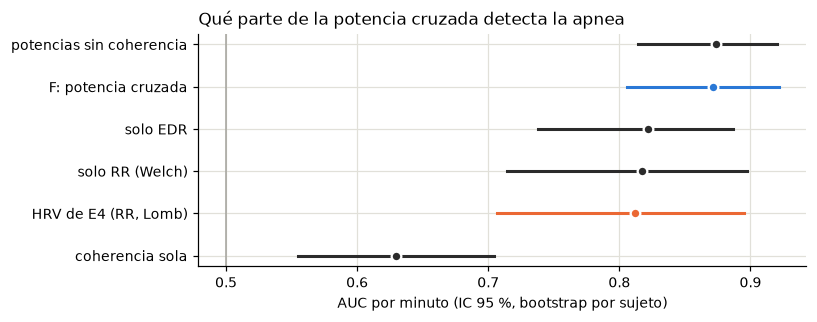

In [6]:
orden = res.sort_values("auc").index
fig, ax = plt.subplots(figsize=(7.5, 3))
for i, v in enumerate(orden):
    c = AZUL if v.startswith("F") else (NARANJA if "HRV" in v else TINTA)
    ax.plot([res.loc[v, "ic_lo"], res.loc[v, "ic_hi"]], [i, i], color=c, lw=2)
    ax.scatter(res.loc[v, "auc"], i, s=40, color=c, edgecolor="white", linewidth=1.5, zorder=3)
ax.axvline(0.5, color=GRIS, lw=1)
ax.set_yticks(range(len(orden)), orden)
ax.set_xlabel("AUC por minuto (IC 95 %, bootstrap por sujeto)")
ax.set_title("Qué parte de la potencia cruzada detecta la apnea", loc="left")
fig.tight_layout(); fig.savefig(FIG / "E3a_descomposicion.png")

## Conclusión

- **La coherencia no aporta.** Las dos potencias sin coherencia (media geométrica de P_RR y P_EDR) dan 0,874, lo mismo que F (0,871; diferencia −0,002, IC −0,010 a +0,004). Según el criterio fijado, son no inferiores a F: la $\sqrt{C}$ que la potencia cruzada tiene adentro no suma de forma relevante. Lo que detecta la apnea es **cuánto oscilan** el RR y el EDR en la banda del ciclo de apnea, no qué tan sincronizados están.
- **Cada señal sola detecta parecido:** solo RR 0,817 (igual que la HRV con Lomb, 0,812) y solo EDR 0,822. El EDR por sí solo, es decir la modulación de la respiración al ritmo de la apnea medida desde el ECG, es tan informativo como la HRV.
- **Juntar las dos señales sube la estimación** (0,874 contra 0,817 del RR solo; +0,056), pero con 19 sujetos el IC de esa ganancia incluye 0 (−0,014 a +0,131). Según el criterio fijado, que el EDR aporte sobre el RR **no queda demostrado** en desarrollo. Es la misma pregunta que H2, y se responde en test.
- **F no cambia:** este control no elige nada. F (potencia cruzada) y las potencias sin coherencia son equivalentes; F queda como se eligió en E3a, y en el informe se describe como "la oscilación conjunta de RR y EDR en la banda de apnea".
- **Qué implica para el proyecto.** H1 (con apnea aparece un acoplamiento lento) sigue siendo un resultado fisiológico. Pero el detector no se apoya en la sincronía: se apoya en sumar al RR la información de la respiración derivada del ECG. El aporte original pasa a ser **usar el EDR, además del RR, en la banda del ciclo de apnea**.